# 04. 교통사고 유형별 분석  (2일차 종합 미션)

지금까지 배운 **불러오기 · 확인 · 인덱스 · 파생컬럼 · 정렬 · 조건필터 · 시각화**를
실제 공공데이터 하나로 이어서 연습합니다.

> 📁 데이터: 한국도로교통공단 **사고유형별 교통사고 통계(2024)**
> `data` 폴더에 CSV 파일을 넣어주세요.

In [1]:
# ------------------------------------------------
# 라이브러리 + 한글 폰트 (환경 자동 감지)
# ------------------------------------------------
import pandas as pd
import matplotlib.pyplot as plt
import platform

system = platform.system()
if system == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif system == 'Darwin':
    plt.rc('font', family='AppleGothic')
else:
    plt.rc('font', family='NanumGothic')   # 코랩·리눅스
plt.rc('axes', unicode_minus=False)

## 1. 데이터 준비

#### 문제 정의
이번 분석에서 답하려는 질문들입니다.
> * 가장 **많이 발생하는** 교통사고 유형은?
> * **사망자·중상자가 많은** 교통사고 유형은?
> * **사망률(사고 한 건당 사망 위험)** 이 높은 교통사고 유형은?
> * 🎯 **많이 나는 사고와 위험한 사고는 과연 같을까?**

#### 데이터 수집
출처: 공공데이터포털 https://www.data.go.kr/data/15070282/fileData.do

#### 데이터프레임 생성
> ⚠️ 한국 공공데이터는 대부분 **CP949** 인코딩입니다. 그냥 읽으면 한글이 깨져요.

In [2]:
data_file = 'data/한국도로교통공단_사고유형별 교통사고 통계_20241231.csv'
df = pd.read_csv(data_file, encoding='cp949')
df

,사고유형대분류,사고유형중분류,사고유형,사고건수,사망자수,중상자수,경상자수,부상신고자수
0,차대사람,횡단중,횡단중,13725,432,6140,7258,676
1,차대사람,차도통행중,차도통행중,3551,126,1358,1886,306
2,차대사람,길가장자리구역통행중,길가장자리구역통행중,2074,28,599,1318,209
3,차대사람,보도통행중,보도통행중,2260,23,686,1437,233
4,차대사람,기타,기타,14737,273,4643,8961,1603
5,차대차,추돌,추돌,30745,343,6590,43616,3246
6,차대차,기타,기타,44496,248,9702,49558,4960
7,차대차,충돌,충돌,76795,517,18660,88876,7041
8,차량단독,충돌,충돌,2588,271,1221,1421,542
9,차량단독,도로이탈,도로이탈 추락,311,58,166,130,42


#### 데이터 확인
* 전체 모양·자료형·결측치를 먼저 파악합니다.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   사고유형대분류  14 non-null     str  
 1   사고유형중분류  14 non-null     str  
 2   사고유형     14 non-null     str  
 3   사고건수     14 non-null     int64
 4   사망자수     14 non-null     int64
 5   중상자수     14 non-null     int64
 6   경상자수     14 non-null     int64
 7   부상신고자수   14 non-null     int64
dtypes: int64(5), str(3)
memory usage: 1.0 KB


In [4]:
print('shape:', df.shape)
df.head()

shape: (14, 8)


,사고유형대분류,사고유형중분류,사고유형,사고건수,사망자수,중상자수,경상자수,부상신고자수
0,차대사람,횡단중,횡단중,13725,432,6140,7258,676
1,차대사람,차도통행중,차도통행중,3551,126,1358,1886,306
2,차대사람,길가장자리구역통행중,길가장자리구역통행중,2074,28,599,1318,209
3,차대사람,보도통행중,보도통행중,2260,23,686,1437,233
4,차대사람,기타,기타,14737,273,4643,8961,1603


#### 인덱스 설정 (계층 인덱스, MultiIndex)
* `대분류 + 사고유형` 두 개를 인덱스로 지정하면, 사고유형이 대분류 아래로 계층 정리됩니다.
* `df.set_index(['컬럼1', '컬럼2'])`

In [5]:
df = df.set_index(['사고유형대분류', '사고유형'])
df.index

MultiIndex([( '차대사람',        '횡단중'),
            ( '차대사람',      '차도통행중'),
            ( '차대사람', '길가장자리구역통행중'),
            ( '차대사람',      '보도통행중'),
            ( '차대사람',         '기타'),
            (  '차대차',         '추돌'),
            (  '차대차',         '기타'),
            (  '차대차',         '충돌'),
            ( '차량단독',         '충돌'),
            ( '차량단독',    '도로이탈 추락'),
            ( '차량단독',    '도로이탈 기타'),
            ( '차량단독',         '기타'),
            ( '차량단독',      '전도/전복'),
            ('철길건널목',      '철길건널목')],
           names=['사고유형대분류', '사고유형'])

#### 컬럼 정리
* 사고유형과 거의 겹치는 `사고유형중분류` 컬럼은 삭제합니다. (`drop(..., axis=1)`)

In [6]:
df = df.drop('사고유형중분류', axis=1)
df

사고건수  사망자수   중상자수   경상자수  부상신고자수
사고유형대분류 사고유형                                         
차대사람    횡단중         13725   432   6140   7258     676
        차도통행중        3551   126   1358   1886     306
        길가장자리구역통행중   2074    28    599   1318     209
        보도통행중        2260    23    686   1437     233
        기타          14737   273   4643   8961    1603
차대차     추돌          30745   343   6590  43616    3246
        기타          44496   248   9702  49558    4960
        충돌          76795   517  18660  88876    7041
차량단독    충돌           2588   271   1221   1421     542
        도로이탈 추락       311    58    166    130      42
        도로이탈 기타       135     8     70     67      24
        기타           4023    98   1367   2380     577
        전도/전복         907    94    351    363     199
철길건널목   철길건널목           2     2      0      0       0

## 2. 분석
아래 **①번(사고건수)** 은 완성 예시입니다. 같은 패턴으로 나머지를 직접 채워보세요.

#### ① 사고건수가 많은 유형  *(완성 예시)*

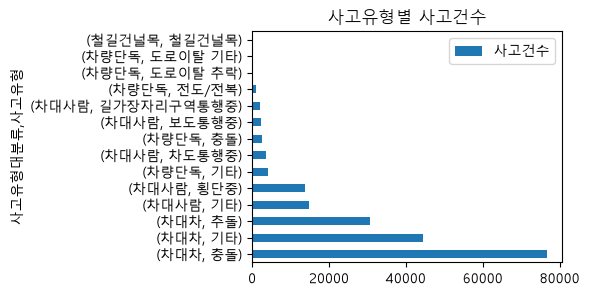

In [15]:
# 막대그래프 (barh: 가로 막대)
# df.sort_values(by='사고건수').plot(kind='barh', y='사고건수',
#                                    figsize=(8, 6), title='사고유형별 사고건수')

df.sort_values(by='사고건수', ascending=False).plot(kind='barh', y='사고건수',
                                                figsize=(4,3), title="사고유형별 사고건수")
pass

#### ② 사망자수가 많은 유형  *(직접)*
* 사망자수 기준으로 정렬하고, 막대그래프로 나타내세요.

<Axes: ylabel='사고유형대분류,사고유형'>

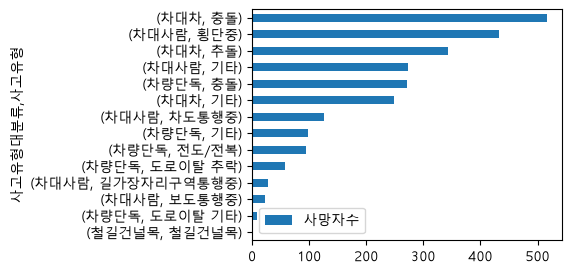

In [ ]:
# TODO: 사망자수 많은 순으로 정렬해 상위 몇 개를 확인하세요.

df.sort_values(by='사망자수').plot(kind='barh', y='사망자수', figsize=(4,3), )

In [ ]:
# TODO: 정렬 결과를 barh 그래프로 그리세요.



#### ③ 중상자수가 많은 유형  *(직접)*

<Axes: ylabel='사고유형대분류,사고유형'>

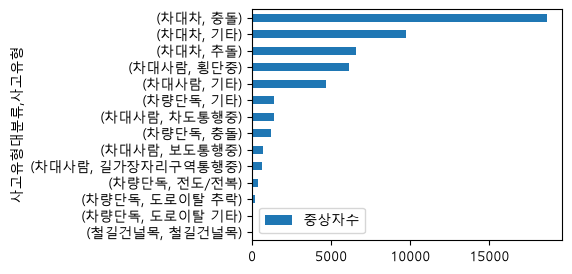

In [26]:
# TODO: 중상자수 많은 순으로 정렬하고 시각화하세요.

df.sort_values('중상자수').plot(figsize=(4,3), kind='barh', y='중상자수')

#### ④ 사망률이 높은 유형  *(직접 · 이 미션의 핵심)*
* **사망률(%) = 사망자수 ÷ 사고건수 × 100** 파생컬럼을 만드세요. (소수점 2자리)
* 사망률 높은 순으로 정렬 + 시각화하세요.
* 💡 사고건수 1위 유형과 사망률 1위 유형을 비교해보세요. 무엇이 보이나요?

In [27]:
# TODO: df['사망률'] = (df['사망자수'] / df['사고건수'] * 100).round(2) 형태로 파생컬럼을 만드세요.

df['사망률'] = (df['사망자수'] / df['사고건수'] * 100).round(2)
df

사고건수  사망자수   중상자수   경상자수  부상신고자수     사망률
사고유형대분류 사고유형                                                 
차대사람    횡단중         13725   432   6140   7258     676    3.15
        차도통행중        3551   126   1358   1886     306    3.55
        길가장자리구역통행중   2074    28    599   1318     209    1.35
        보도통행중        2260    23    686   1437     233    1.02
        기타          14737   273   4643   8961    1603    1.85
차대차     추돌          30745   343   6590  43616    3246    1.12
        기타          44496   248   9702  49558    4960    0.56
        충돌          76795   517  18660  88876    7041    0.67
차량단독    충돌           2588   271   1221   1421     542   10.47
        도로이탈 추락       311    58    166    130      42   18.65
        도로이탈 기타       135     8     70     67      24    5.93
        기타           4023    98   1367   2380     577    2.44
        전도/전복         907    94    351    363     199   10.36
철길건널목   철길건널목           2     2      0      0       0  100.00

In [33]:
# TODO: 사망률 높은 순으로 정렬하세요.

df.sort_values('사망률', ascending=False)

사고건수  사망자수   중상자수   경상자수  부상신고자수     사망률
사고유형대분류 사고유형                                                 
철길건널목   철길건널목           2     2      0      0       0  100.00
차량단독    도로이탈 추락       311    58    166    130      42   18.65
        충돌           2588   271   1221   1421     542   10.47
        전도/전복         907    94    351    363     199   10.36
        도로이탈 기타       135     8     70     67      24    5.93
차대사람    차도통행중        3551   126   1358   1886     306    3.55
        횡단중         13725   432   6140   7258     676    3.15
차량단독    기타           4023    98   1367   2380     577    2.44
차대사람    기타          14737   273   4643   8961    1603    1.85
        길가장자리구역통행중   2074    28    599   1318     209    1.35
차대차     추돌          30745   343   6590  43616    3246    1.12
차대사람    보도통행중        2260    23    686   1437     233    1.02
차대차     충돌          76795   517  18660  88876    7041    0.67
        기타          44496   248   9702  49558    4960    0.56

<Axes: ylabel='사고유형대분류,사고유형'>

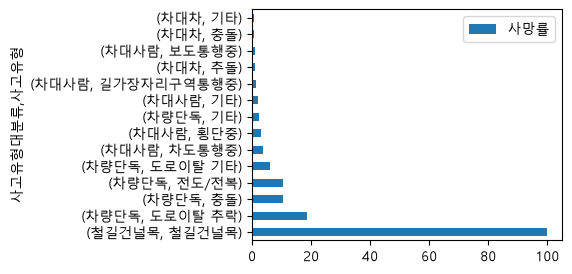

In [34]:
# TODO: 사망률을 막대그래프로 그리세요.

df.sort_values('사망률', ascending=False).plot(figsize=(4,3), y='사망률', kind='barh')

#### ⑤ 평균보다 위험한 유형 골라내기  *(직접 · 조건필터)*
* 사망률이 **전체 평균보다 높은** 사고유형만 뽑아보세요.
* 힌트: `조건 = df['사망률'] > df['사망률'].mean()` → `df.loc[조건]`

In [35]:
# TODO: df['사망률'].mean() 보다 큰 행만 df.loc[조건] 으로 골라내세요.

df.loc[df['사망률'] > df['사망률'].mean()]

,,사고건수,사망자수,중상자수,경상자수,부상신고자수,사망률
사고유형대분류,사고유형,,,,,,
차량단독,도로이탈 추락,311,58,166,130,42,18.65
철길건널목,철길건널목,2,2,0,0,0,100.00


#### ⑥ 대분류별로 묶어 보기  *(맛보기 · groupby)*
* 개별 유형 말고 **대분류(차대사람/차대차/차량단독)** 단위로 합계를 보면 큰 그림이 보입니다.
* 아래 한 줄이면 됩니다. 💡 이 `groupby`는 **11번(그룹화)** 에서 제대로 배웁니다. 지금은 맛보기!

In [38]:
# 대분류(인덱스 레벨 0)로 묶어서 합계
df.groupby(level='사고유형대분류')[['사고건수', '사망자수', '중상자수']].sum()

,사고건수,사망자수,중상자수
사고유형대분류,,,
차대사람,36347,882,13426
차대차,152036,1108,34952
차량단독,7964,529,3175
철길건널목,2,2,0


## 3. 결론 도출
* 위 분석을 바탕으로 **처음의 질문에 답**해보세요.
* 산출물: 시각화 결과 캡처 + 분석 내용 3~4줄 정리

예) 사고는 `충돌(차대차)`이 가장 많지만, 사망률로 보면 `도로이탈 추락`이 훨씬 위험하다 …

### 🏆 도전과제  *(빨리 끝냈다면)*
1. **사고는 적게 나지만 유난히 치명적인**(사망률 높은) 사고유형 3가지를 찾고, 왜 위험한지 한 줄씩 해석하세요.
2. `중상률(%) = 중상자수 ÷ 사고건수 × 100` 파생컬럼도 만들어 사망률과 비교해보세요.
3. 🤔 `철길건널목`은 사망률이 100%로 1위인데, 이걸 '가장 위험한 사고'라고 단정하기 어려운 이유는? (힌트: 사고건수를 보세요)
4. 이 데이터로 뉴스 헤드라인 한 줄을 뽑아본다면?